# **Árvores de Decisão: Investigando a Hipótese do Titanic**

## 1. Os Problema nos Algoritmos
Até agora, vimos algoritmos poderosos como as **Máquinas de Vetores de Suporte (SVM)** e o **Naïve Bayes**. No entanto, uma crítica muito comum a esses métodos estatísticos e lineares é que eles funcionam quase como uma **"caixa-preta"**: é muito difícil explicar para um ser humano *como* o modelo chegou àquela decisão final.

* **No SVM:** Se tivermos dezenas de características (alta dimensionalidade), é impossível para a mente humana visualizar ou desenhar o hiperplano que separa as classes.
* **No Naïve Bayes:** O algoritmo apenas nos dirá algo como *"esta classe é a mais provável assumindo que os dados seguem a mesma distribuição do treino e que as variáveis são independentes"*. 

Isso não ajuda muito quando precisamos justificar o **motivo** real de uma decisão. Imagine um médico precisando explicar um diagnóstico (como vimos no caso do AVC) ou um banco negando um empréstimo: não basta dizer *"foi o computador que mandou"*, precisamos entender a regra lógica por trás da escolha!

## 2. Funcionamento uma Árvore de Decisão
As **Árvores de Decisão** (*Decision Trees*) são métodos de aprendizado supervisionado simples, mas extremamente poderosos, que resolvem o problema da interpretação. Elas funcionam exatamente como um fluxograma de perguntas e respostas (ou como aquele clássico jogo de tabuleiro *"Cara a Cara"*).

Veja abaixo a recriação de uma árvore de decisão muito simples para decidir se um e-mail é **Spam** ou **Ham** (e-mail confiável/desejado):

<div style="text-align: center; margin: 20px 0;">
    <img src="spam_ou_ham.jpg" alt="Exemplo de Árvore de Decisão: Spam ou Ham" style="width: 60%; max-width: 600px; height: auto; border-radius: 6px; box-shadow: 0 4px 8px rgba(0,0,0,0.15);">
    <p style="font-size: 0.9em; color: #555; margin-top: 8px;">
        <i>Exemplo de uma Árvore de Decisão simples para classificação de e-mails (Spam ou Ham).</i>
    </p>
</div>

> **Por que esse modelo é tão vantajoso?**
> Qualquer pessoa consegue acompanhar o caminho das setas e entender exatamente por que o e-mail foi bloqueado ou liberado!


## 3. O Nosso Desafio: A Tragédia do Titanic  

Na noite de 14 de abril de 1912, o RMS Titanic — o maior e mais luxuoso navio de passageiros de sua época — colidiu com um iceberg em sua viagem inaugural pelo Oceano Atlântico. Considerado "inafundável", o transatlântico afundou na madrugada do dia seguinte, resultando em uma das maiores catástrofes marítimas em tempos de paz da história moderna.  

A tragédia não foi apenas um desastre de engenharia, mas um evento social impactante. O navio operava sob um rígido sistema de classes sociais e uma forte cultura eduardiana de códigos de conduta (como o protocolo "mulheres e crianças primeiro"). Diante da escassez de botes salva-vidas, que podiam abrigar apenas metade das pessoas a bordo, esses fatores sociais e demográficos tornaram-se determinantes biológicos entre a vida e a morte.  

Historicamente, o Titanic transportava cerca de 1.317 passageiros pagantes (além de cerca de 891 tripulantes). Para fins de ciência de dados e modelagem preditiva, o conjunto de dados padrão internacionalmente consolidado (frequentemente utilizado em plataformas como o Kaggle e repositórios acadêmicos) foca estritamente em 1.309 passageiros.

Nesta aula, vamos colocar o computador para investigar um dos eventos históricos mais famosos do mundo: o naufrágio do **Titanic**. 

<div style="text-align: center; margin: 20px 0;">
    <img src="rms-titanic-14047.png" alt="RMS Titanic" style="width: 50%; height: auto; border-radius: 6px;">
    <p style="font-size: 0.9em; color: #555; margin-top: 8px;">
        <i>Fotografia do RMS Titanic partindo de Southampton em sua fatídica viagem inaugural em 10 de abril de 1912.</i>
    </p>
</div>

O nosso objetivo é determinar se um passageiro teria sobrevivido ou não à tragédia baseando-se em apenas três características: **Idade (`age`)**, **Classe da Cabine (`pclass`)** e **Sexo (`sex`)**. Será que a famosa regra *"mulheres e crianças primeiro"* realmente aconteceu na prática? A nossa árvore de decisão vai nos contar!

### 3.1 Explorando o Conjunto de Dados 
Trabalharemos com o conjunto de dados oficial do Titanic, que inclui a lista de **1.309 passageiros** e uma coluna indicando se sobreviveram ou não. Cada linha no arquivo tem o seguinte formato:

`"1","1","Allen, Miss. Elisabeth Walton","female","29","0","0","24160","211.3375","B5","S","2","","St Louis, MO"`

Ao todo, temos **14 atributos (colunas)** registrados na base:
* `pclass` (Índice `0`): Classe do passageiro (`1` = 1ª, `2` = 2ª, `3` = 3ª classe)
* `survived` (Índice `1`): **Nosso Alvo/Gabarito** (`0` = Não sobreviveu, `1` = Sobreviveu)
* `name` (Índice `2`): Nome completo do passageiro
* `sex` (Índice `3`): Sexo (`male` ou `female`)
* `age` (Índice `4`): Idade em anos
* `sibsp` (Índice `5`): Número de irmãos/cônjuges a bordo
* `parch` (Índice `6`): Número de pais/filhos a bordo
* `ticket` (Índice `7`): Número da passagem
* `fare` (Índice `8`): Valor pago pela tarifa
* `cabin` (Índice `9`): Número do quarto/cabine
* `embarked` (Índice `10`): Porto de embarque (`C`, `Q` ou `S`)
* `boat` (Índice `11`): Número do bote salva-vidas
* `body` (Índice `12`): Número de identificação do corpo
* `home.dest` (Índice `13`): Origem / Destino

Vamos começar carregando o arquivo `titanic3.csv` diretamente em matrizes do `numpy` usando o módulo nativo `csv` do Python.

In [1]:
import csv
import numpy as np

# Abrindo o arquivo titanic3.csv 
with open('titanic3.csv', 'r', encoding='utf-8') as csvfile:
    titanic_reader = csv.reader(csvfile, delimiter=',', quotechar='"')
    
    # A primeira linha (cabeçalho) contém os nomes das colunas (features)
    row = next(titanic_reader)
    feature_names = np.array(row)
    
    # Carregando os dados (X) e as classes alvo (y)
    titanic_X, titanic_y = [], []
    for row in titanic_reader:
        # Ignora linhas em branco no final do arquivo
        if len(row) > 0 and row[0] != '':
            titanic_X.append(row)
            titanic_y.append(row[1]) # O valor alvo é "survived" (índice 1 no titanic3.csv)
            
    titanic_X = np.array(titanic_X)
    titanic_y = np.array(titanic_y)

In [2]:
# Imprimindo os nomes das colunas
print("Colunas do Dataset:")
print(feature_names)

print("\nDados da Primeira Passageira (X):")
print(titanic_X[0])

print("\nSobreviveu? (y):", titanic_y[0])

Colunas do Dataset:
['pclass' 'survived' 'name' 'sex' 'age' 'sibsp' 'parch' 'ticket' 'fare'
 'cabin' 'embarked' 'boat' 'body' 'home.dest']

Dados da Primeira Passageira (X):
['1' '1' 'Allen, Miss. Elisabeth Walton' 'female' '29' '0' '0' '24160'
 '211.3375' 'B5' 'S' '2' '' 'St Louis, MO']

Sobreviveu? (y): 1


## 4. Pré-processamento dos Dados 

O primeiro passo prático em qualquer projeto de Machine Learning é escolher **quais colunas (atributos)** vamos entregar para o algoritmo estudar. Esse processo é chamado de **Seleção de Características (*Feature Selection*)**.

Se entregarmos dados ruins ou irrelevantes como entrada, o modelo não terá material de qualidade para aprender — no jargão da computação, chamamos isso de *"Garbage In, Garbage Out"* (Lixo entra, Lixo sai). Não importa se você tem o algoritmo mais avançado do mundo: sem boas variáveis, o resultado será ruim!

<div style="background-color: #252526; border-left: 5px solid #ce9178; padding: 15px; margin: 15px 0; border-radius: 4px; color: #d4d4d4;">
<b style="color: #ce9178;">⚠️ Por que não usamos o Nome ou o Número da Cabine?</b><br>
Atributos específicos demais (como o <code>name</code> do passageiro) causam <b>Overfitting (Sobreajuste)</b>. Imagine uma árvore de decisão que simplesmente decora a lista de chamadas e pergunta: <i>"O nome da pessoa é Elisabeth Walton Allen? Se sim, sobreviveu!"</i>. Essa regra funciona para o treino, mas é completamente inútil para prever o destino de novos passageiros!
</div>

Por conhecimento prévio do problema, sabemos que a **Classe (`pclass`)**, a **Idade (`age`)** e o **Sexo (`sex`)** foram determinantes no protocolo de evacuação do navio. No nosso arquivo `titanic3.csv`, essas três colunas estão nos índices **`0`**, **`4`** e **`3`**. Vamos filtrá-las!

In [3]:
# Mantemos apenas a Classe (índice 0), Idade (índice 4) e Sexo (índice 3)
titanic_X = titanic_X[:, [0, 4, 3]]
feature_names = feature_names[[0, 4, 3]]

print("Colunas selecionadas:", feature_names)
print("Exemplo do passageiro de índice 15:", titanic_X[15], "| Sobreviveu?", titanic_y[15])

Colunas selecionadas: ['pclass' 'age' 'sex']
Exemplo do passageiro de índice 15: ['1' '' 'male'] | Sobreviveu? 0


### 4.1 O Problema dos Dados Ausentes (*Missing Values*)
Observe atentamente a saída do passageiro de número `15` acima: `['1' '' 'male']`. 
Temos um problema clássico da Ciência de Dados: **a idade dele não foi registrada** (está vazia `''`)! No caos do naufrágio, muitos registros se perderam.

O algoritmo não consegue fazer contas com um espaço vazio. Para resolver isso, vamos substituir as idades vazias pela **média de idade (`mean`)** de todos os outros passageiros (que é de aproximadamente **29,88 anos**). 

> **💡 Regra de Ouro do Cientista de Dados:** Poderíamos usar a mediana ou o valor mais frequente (moda). Porém, sempre que preenchemos dados faltantes, estamos modificando o problema original. Faça isso com cautela e consciência para não distorcer os resultados finais!

In [4]:
# Isolando a coluna de idades (agora no índice 1 da nossa nova matriz titanic_X)
ages = titanic_X[:, 1]

# Calculando a média apenas dos passageiros que possuem idade preenchida (diferente de '')
mean_age = np.mean(titanic_X[ages != '', 1].astype(float))
print(f"Média de idade calculada: {mean_age:.2f} anos")

# Atribuindo a média onde a idade está vazia ('')
titanic_X[titanic_X[:, 1] == '', 1] = mean_age

print("Passageiro 15 após o preenchimento:", titanic_X[15])

Média de idade calculada: 29.88 anos
Passageiro 15 após o preenchimento: ['1' '29.8811345124283' 'male']


### 4.2 Traduzindo Categorias para Números (`LabelEncoder`)
A implementação de Árvores de Decisão no `scikit-learn` exige que todas as entradas sejam **números reais**, pois o algoritmo constrói regras matemáticas do tipo:
* `Característica <= Valor` (por exemplo: `idade <= 20.0`).

A idade já é numérica, mas o **Sexo (`sex`)** é um atributo **categórico** (texto: `'female'` ou `'male'`). 
Para converter texto em número de forma automática, usamos a ferramenta **`LabelEncoder`** do módulo `sklearn.preprocessing`. Ela transforma um conjunto de $K$ categorias em números inteiros de $0$ até $K-1$:
* `'female'` $\rightarrow$ **`0`**
* `'male'` $\rightarrow$ **`1`**

In [5]:
from sklearn.preprocessing import LabelEncoder

# Criando o codificador e treinando na coluna Sexo (índice 2)
enc = LabelEncoder()
label_encoder = enc.fit(titanic_X[:, 2])

print("Classes categóricas encontradas:", label_encoder.classes_)

integer_classes = label_encoder.transform(label_encoder.classes_)
print("Classes convertidas para inteiros:", integer_classes)

# Aplicando a transformação na nossa matriz de dados
t = label_encoder.transform(titanic_X[:, 2])
titanic_X[:, 2] = t

print("\n Colunas atuais:", feature_names)
print("Passageiro 15 atualizado:", titanic_X[15], "| Sobreviveu?", titanic_y[15])

Classes categóricas encontradas: ['female' 'male']
Classes convertidas para inteiros: [0 1]

 Colunas atuais: ['pclass' 'age' 'sex']
Passageiro 15 atualizado: ['1' '29.8811345124283' '1'] | Sobreviveu? 0


### 4.3 Eliminando Hierarquias Falsas com *One-Hot Encoding*
Ainda temos mais um atributo categórico: a **Classe da Cabine (`pclass`)**, que possui três valores (`1`, `2` e `3` — representando a 1ª, 2ª e 3ª classe).

Se usássemos apenas o `LabelEncoder` para convertê-las em `0`, `1` e `2`, estaríamos impondo uma relação de grandeza matemática onde a 3ª classe (`2`) vale "o dobro" da 2ª classe (`1`). Em muitos problemas, criar uma ordenação artificial confunde o algoritmo.

Para evitar isso, usamos uma técnica universal chamada **One-Hot Encoding** (`OneHotEncoder`). Em vez de uma única coluna com valores `0, 1, 2`, criamos **três novas colunas binárias** (como interruptores de luz: `1` = Sim, `0` = Não):

<table style="width: 75%; margin: 15px auto; border-collapse: collapse; text-align: center; font-family: sans-serif;">
<tr style="background-color: #007acc; color: white;">
<th style="padding: 8px; border: 1px solid #444;">Classe Original</th>
<th style="padding: 8px; border: 1px solid #444;">first_class</th>
<th style="padding: 8px; border: 1px solid #444;">second_class</th>
<th style="padding: 8px; border: 1px solid #444;">third_class</th>
</tr>
<tr>
<td style="padding: 8px; border: 1px solid #444;"><b>1ª Classe</b></td>
<td style="padding: 8px; border: 1px solid #444; color: #4ec9b0; font-weight: bold;">1.0</td>
<td style="padding: 8px; border: 1px solid #444;">0.0</td>
<td style="padding: 8px; border: 1px solid #444;">0.0</td>
</tr>
<tr>
<td style="padding: 8px; border: 1px solid #444;"><b>2ª Classe</b></td>
<td style="padding: 8px; border: 1px solid #444;">0.0</td>
<td style="padding: 8px; border: 1px solid #444; color: #4ec9b0; font-weight: bold;">1.0</td>
<td style="padding: 8px; border: 1px solid #444;">0.0</td>
</tr>
<tr>
<td style="padding: 8px; border: 1px solid #444;"><b>3ª Classe</b></td>
<td style="padding: 8px; border: 1px solid #444;">0.0</td>
<td style="padding: 8px; border: 1px solid #444;">0.0</td>
<td style="padding: 8px; border: 1px solid #444; color: #4ec9b0; font-weight: bold;">1.0</td>
</tr>
</table>

Por fim, removemos a coluna `pclass` original e convertemos toda a nossa matriz para números decimais (`float`). 

> **Nota sobre Escalonamento:** Ao contrário do SVM, nas Árvores de Decisão **não precisamos normalizar ou padronizar a escala dos dados**, pois comparar a magnitude relativa entre duas colunas diferentes (como Idade vs. Classe) não afeta a criação das regras da árvore!

In [6]:
from sklearn.preprocessing import OneHotEncoder

# 1. Transformamos as classes ('1', '2', '3') em inteiros (0, 1, 2)
enc = LabelEncoder()
label_encoder = enc.fit(titanic_X[:, 0])
print("Classes da Cabine:", label_encoder.classes_)

integer_classes = label_encoder.transform(label_encoder.classes_).reshape(3, 1)
print("Classes como inteiros:\n", integer_classes)

# 2. Configuramos o OneHotEncoder para criar as 3 novas colunas binárias
enc = OneHotEncoder()
one_hot_encoder = enc.fit(integer_classes)

num_of_rows = titanic_X.shape[0]
t = label_encoder.transform(titanic_X[:, 0]).reshape(num_of_rows, 1)
new_features = one_hot_encoder.transform(t)

# 3. Adicionamos as 3 novas colunas ao final da matriz titanic_X
titanic_X = np.concatenate([titanic_X, new_features.toarray()], axis=1)

# 4. Removemos a coluna original de classe (que estava no índice 0)
titanic_X = np.delete(titanic_X, [0], 1)

# 5. Atualizamos a lista com os novos nomes das 5 colunas e convertemos tudo para float
feature_names = ['age', 'sex', 'first_class', 'second_class', 'third_class']
titanic_X = titanic_X.astype(float)
titanic_y = titanic_y.astype(float)

print("\nNovas colunas prontas para a Árvore de Decisão:")
print(feature_names)
print("\nPrimeira passageira (X) e seu Alvo (y):")
print(titanic_X[0], titanic_y[0])

Classes da Cabine: ['1' '2' '3']
Classes como inteiros:
 [[0]
 [1]
 [2]]

Novas colunas prontas para a Árvore de Decisão:
['age', 'sex', 'first_class', 'second_class', 'third_class']

Primeira passageira (X) e seu Alvo (y):
[29.  0.  1.  0.  0.] 1.0


# 5. Treinando um Classificador de Árvore de Decisão
Agora chegamos à parte mais interessante: vamos construir uma Árvore de Decisão a partir dos nossos dados de treinamento. Como de costume em projetos de Machine Learning, o primeiro passo é separar nosso conjunto de dados em dados de treinamento e dados de teste.


In [8]:
from sklearn.model_selection import train_test_split

# Separando os dados: 75% para treinamento e 25% para teste
X_train, X_test, y_train, y_test = train_test_split(
    titanic_X, 
    titanic_y, 
    test_size=0.25, 
    random_state=33
)

Com os dados separados, podemos instanciar um novo `DecisionTreeClassifier` e utilizar o método `fit()` para realizar o processo de aprendizado.

Assim como a maioria dos algoritmos de aprendizado, a Árvore de Decisão aceita diversos **hiperparâmetros** que controlam o seu comportamento. Neste caso, configuramos o modelo para:

* `criterion='entropy'`: Utilizar o Ganho de Informação (Entropia) como critério para dividir os dados.
* `max_depth=3`: Construir uma árvore com, no máximo, 3 níveis de profundidade.
* `min_samples_leaf=5`: Exigir que um nó final (folha) tenha pelo menos 5 amostras de treinamento para ser criado.

In [9]:
from sklearn import tree

# Instanciando e treinando o classificador
clf = tree.DecisionTreeClassifier(criterion='entropy', max_depth=3, min_samples_leaf=5)
clf = clf.fit(X_train, y_train)

### 5.1. Visualizando e Interpretando o Modelo

Para explicar como as árvores de decisão funcionam, vamos visualizar o modelo construído. Antigamente, isso exigia a instalação de pacotes externos complexos como o Graphviz e o pydot. Hoje, podemos gerar essa visualização de forma muito mais simples utilizando as funções nativas de plotagem do próprio scikit-learn em conjunto com o matplotlib.

Matplotlib is building the font cache; this may take a moment.


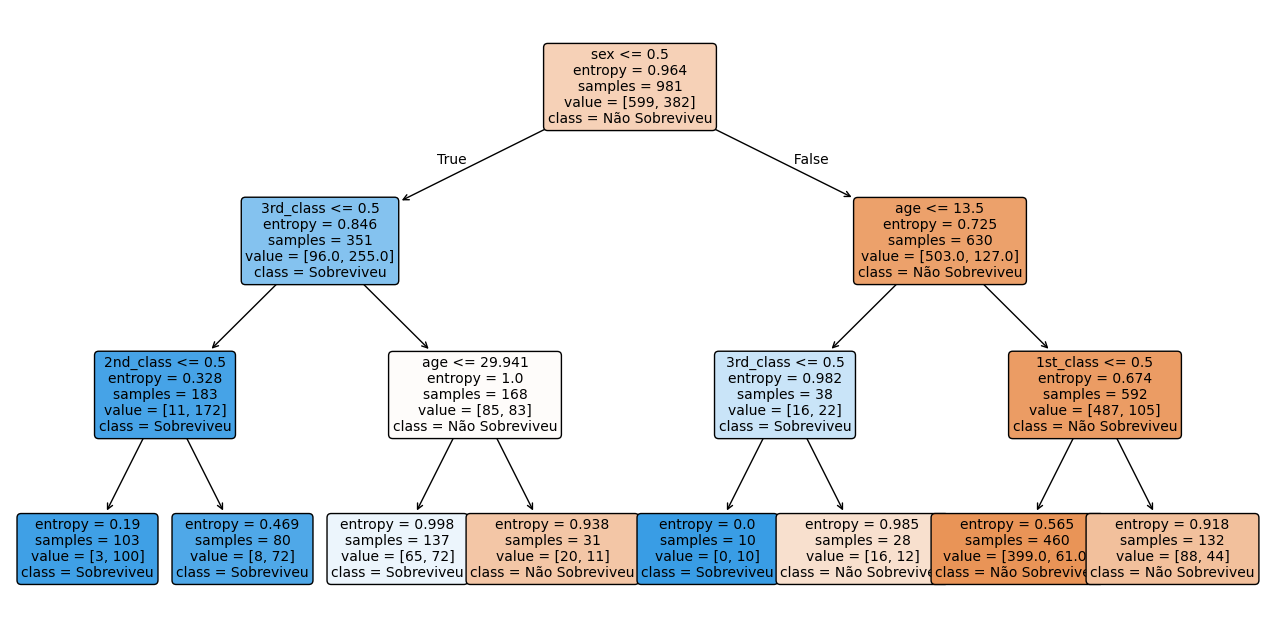

In [10]:
import matplotlib.pyplot as plt

# Configurando o tamanho da figura
plt.figure(figsize=(16, 8))

# Desenhando a árvore de decisão
tree.plot_tree(
    clf,
    feature_names=['age', 'sex', '1st_class', '2nd_class', '3rd_class'],
    class_names=['Não Sobreviveu', 'Sobreviveu'],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.show()

A árvore de decisão que acabamos de construir representa uma série de decisões baseadas nos dados de treinamento. Para classificar um novo passageiro, o modelo responde às perguntas de cada nó da árvore, começando pelo topo.

* **O Nó Raiz (Root Node):** Por exemplo, a primeira pergunta no topo da nossa árvore pode ser algo como *"O sexo é <= 0.5?"* (ou seja, estamos falando de uma mulher?). Se a resposta for sim, seguimos para o nó filho à esquerda; se não, seguimos para o nó à direita.
* **O Caminho:** Continuamos respondendo às perguntas (*"Estava na terceira classe?"*, *"Tinha menos de 13 anos?"*) até chegarmos ao final de um ramo.
* **As Folhas (Leaf Nodes):** Quando chegamos a um nó sem filhos (uma folha), a previsão final corresponde à classe alvo que possui a maioria das instâncias naquele grupo. No nosso caso, se o caminho indicar que a passageira era uma mulher da segunda classe, a resposta final provavelmente será 1 (Sobreviveu).

#### Mas como o algoritmo escolhe as perguntas?

Você pode estar se perguntando como o método decide quais perguntas devem ser feitas e em qual ordem. A resposta está no **Ganho de Informação (Information Gain)** ou na **Entropia** (o scikit-learn também utiliza o Índice Gini, que é uma medida de desordem muito semelhante).

O Ganho de Informação mede quanta "entropia" nós perdemos ao responder a uma pergunta — ou, em outras palavras, o quanto ficamos mais "certos" sobre a classificação após dividirmos os dados. A **Entropia** é uma medida matemática da desordem de um conjunto:

* **Entropia = 0:** Significa que o conjunto está perfeitamente puro. Todas as instâncias pertencem à mesma classe (ex: todos sobreviveram).
* **Entropia Máxima:** Ocorre quando há um número exatamente igual de instâncias de cada classe (ex: metade sobreviveu e metade não sobreviveu), representando incerteza total.

A cada nó, o algoritmo analisa as instâncias disponíveis e mede a entropia. Ele testará várias perguntas possíveis e selecionará aquela que gerar a divisão mais **homogênea** (com a menor entropia resultante nos nós filhos). O processo se repete até que a árvore atinja as condições de parada definidas (como a profundidade máxima de 3 níveis que configuramos).

# 6. Interpretando a Árvore de Decisão

Como podemos observar no gráfico da árvore, no início do processo tínhamos todas as 984 instâncias do nosso conjunto de treinamento. Dessas, 662 correspondiam à classe 0 (não sobreviventes) e 322 à classe 1 (sobreviventes). A entropia medida para esse grupo inicial era de aproximadamente 0.632. 

Dentre as perguntas possíveis de serem feitas, a que gerou o maior **Ganho de Informação** foi: *"O passageiro era do sexo feminino?"* (lembrando que a categoria feminina foi codificada como 0). Se a resposta for **sim**, a entropia quase não muda, mas se a resposta for **não**, a entropia diminui drasticamente (pois a proporção de homens que morreram foi muito maior do que a taxa geral de mortes). Por esse motivo, essa foi a melhor pergunta inicial a ser feita pelo algoritmo.

A partir daí, o processo continua recursivamente, analisando em cada nó apenas o subconjunto de dados que atende às condições do caminho percorrido até ali.

Cada nó nos mostra:
* A pergunta condicional.
* A entropia do grupo de dados naquele ponto.
* O número total de amostras (*samples*) sendo consideradas.
* A distribuição de classes (*value*), indicando quantos pertencem a cada classe.

O processo de divisão se repete até atingir um critério de parada (no nosso caso, a profundidade máxima de 3 níveis ou o limite mínimo de 5 amostras em um nó).

### 6.1. Como o modelo faz uma previsão?

Para classificar um novo passageiro, iniciamos no topo da árvore (nó raiz) e respondemos às perguntas com base nos atributos daquela pessoa. Se a resposta for **sim**, seguimos pelo ramo da esquerda; se for **não**, seguimos pelo ramo da direita. Repetimos esse processo até atingir uma folha, onde a previsão final será a classe dominante daquele grupo.

**Exemplo Prático:**
Imagine que queremos prever se uma **menina de 10 anos, viajando na primeira classe**, teria sobrevivido:

1. **É do sexo feminino?** Sim $\rightarrow$ seguimos para o ramo da esquerda.
2. **É da terceira classe?** Não $\rightarrow$ seguimos para o ramo da direita.
3. **É da primeira classe?** Sim $\rightarrow$ seguimos para o nó correspondente.

Chegamos a uma folha. No conjunto de treinamento, tínhamos 102 pessoas com esse exato perfil, sendo 97 sobreviventes. Portanto, a previsão do modelo para ela é: **Sobreviveu**.

De modo geral, o modelo encontrou padrões bastante coerentes com a história: o grupo com mais vítimas fatais (449 de 496) foi o de homens adultos da 2ª e 3ª classes, enquanto a maioria das meninas da 1ª classe sobreviveu.  

<div align="center">
    <img src="rose-e-jack-em-cena-de-titanic.jpg" alt="Cena do filme Titanic com Jack e Rose" width="50%">
    <p><i>Cena icônica do filme Titanic ilustrando a diferença nas chances de sobrevivência entre os passageiros.</i></p>
</div>

### 6.2. Avaliando o Desempenho no Conjunto de Treinamento

Para medir o quão bem a nossa árvore se ajustou aos dados, podemos criar uma função auxiliar para exibir as métricas de avaliação.

In [11]:
from sklearn import metrics

def measure_performance(X, y, clf, show_accuracy=True, show_classification_report=True, show_confusion_matrix=True):
    # Realiza as predições para o conjunto fornecido
    y_pred = clf.predict(X)
    
    if show_accuracy:
        print(f"Acurácia: {metrics.accuracy_score(y, y_pred):.3f}\n")
        
    if show_classification_report:
        print("Relatório de Classificação:")
        print(metrics.classification_report(y, y_pred), "\n")
        
    if show_confusion_matrix:
        print("Matriz de Confusão:")
        print(metrics.confusion_matrix(y, y_pred), "\n")

# Medindo a acurácia apenas no conjunto de treinamento
measure_performance(X_train, y_train, clf, show_classification_report=False, show_confusion_matrix=False)

Acurácia: 0.792



Nossa árvore alcançou uma acurácia de **0.838 (83,8%)** nos dados de treinamento. No entanto, medir o desempenho no próprio conjunto de treinamento é um mau indicador, pois Árvores de Decisão são muito suscetíveis ao **overfitting** (decorar os dados de treino em vez de aprender a generalizar).

Para obter uma avaliação mais confiável sem usar o conjunto de teste antecipadamente, podemos aplicar a **Validação Cruzada Leave-One-Out (LOOCV)**. Nesse método, se temos $N$ amostras, o modelo é treinado $N$ vezes utilizando $N-1$ amostras e testado na única amostra que foi deixada de fora. A acurácia final é a média das predições de cada uma dessas etapas.

In [12]:
import numpy as np
from sklearn.model_selection import LeaveOneOut
from scipy.stats import sem

def loo_cv(X_train, y_train, clf):
    # Instancia a validação cruzada Leave-One-Out
    loo = LeaveOneOut()
    scores = np.zeros(X_train.shape[0])
    
    # Itera sobre cada divisão do conjunto de treinamento
    for train_index, test_index in loo.split(X_train):
        X_train_cv, X_test_cv = X_train[train_index], X_train[test_index]
        y_train_cv, y_test_cv = y_train[train_index], y_train[test_index]
        
        # Treina e avalia na amostra isolada
        clf_fitted = clf.fit(X_train_cv, y_train_cv)
        y_pred = clf_fitted.predict(X_test_cv)
        
        scores[test_index] = metrics.accuracy_score(y_test_cv.astype(int), y_pred.astype(int))
        
    print(f"Pontuação Média (LOOCV): {np.mean(scores):.3f} (+/-{sem(scores):.3f})")

# Executando a validação cruzada LOOCV
loo_cv(X_train, y_train, clf)

Pontuação Média (LOOCV): 0.781 (+/-0.013)


A acurácia média obtida com a validação cruzada foi de **0.837 (83,7%)**.

A grande vantagem da validação *Leave-One-Out* é utilizar praticamente quase todos os dados disponíveis para treino em cada iteração, sendo ideal quando a base de dados é reduzida. Por outro lado, seu custo computacional é elevado, pois exige treinar um modelo novo para cada amostra.

Uma questão importante permanece: **como escolhemos os melhores hiperparâmetros (como profundidade máxima e número mínimo de folhas) para o nosso modelo?** 

Esse processo de escolha e ajuste é conhecido como **Seleção de Modelos (Model Selection)**.

# Fontes  

1. https://hbiostat.org/data/
2. https://www.worldhistory.org/image/14047/rms-titanic/